<a href="https://colab.research.google.com/github/RISHABH12005/AIESE/blob/main/Lecture/L20/ML_Test_Case_Prioritization_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-Based Test Case Prioritization

**Goal:** Demonstrate how a model can estimate which test cases are more likely to detect failures, then use those estimates to suggest an execution order.

**Important:** This notebook uses a small **synthetic demonstration dataset**, not the original AutoTCP paper dataset. It is intended to teach the workflow and must not be presented as a reproduction of the AutoTCP research results.

### Learning outcomes
- Understand test case features and historical labels.
- Train a baseline classifier.
- Estimate failure-detection probabilities.
- Rank test cases and compare the ranking with a simple baseline.

Run the cells in order in Google Colab.

## Cell 1 — Install required libraries

This cell installs pandas, NumPy, scikit-learn, and Matplotlib for data handling, model training, and plotting.

In [1]:
%pip -q install pandas numpy scikit-learn matplotlib

## Cell 2 — Create illustrative historical test execution data

Each row represents a past test execution. Features include the number of previous failures, whether related code changed, and execution time. The label `detected_defect` is `1` when a defect was detected in that recorded execution and `0` otherwise.

These values are invented for teaching; they are not real project records or the paper's data.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    "test_case": [
        "Login", "Payment", "Search", "Checkout",
        "Profile", "Refund", "Registration", "Cart",
        "Order", "Password_Reset", "Address", "Discount",
        "Shipping", "Invoice", "Wishlist", "Logout",
        "Coupon", "Inventory", "Notification", "Review"
    ],
    "previous_failures": [0, 5, 1, 4, 0, 3, 2, 1, 4, 0, 1, 3, 2, 4, 0, 1, 3, 5, 1, 2],
    "code_changed":       [0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1],
    "execution_time":     [2, 8, 3, 7, 2, 6, 4, 3, 7, 2, 3, 5, 4, 6, 2, 2, 5, 8, 3, 4],
    "detected_defect":    [0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1]
}

df = pd.DataFrame(data)
display(df.head(10))
print("Total historical executions:", len(df))
print("\nLabel distribution:")
print(df["detected_defect"].value_counts())

,test_case,previous_failures,code_changed,execution_time,detected_defect
0,Login,0,0,2,0
1,Payment,5,1,8,1
2,Search,1,0,3,0
3,Checkout,4,1,7,1
4,Profile,0,0,2,0
5,Refund,3,1,6,1
6,Registration,2,1,4,1
7,Cart,1,0,3,0
8,Order,4,1,7,1
9,Password_Reset,0,0,2,0


Total historical executions: 20

Label distribution:
detected_defect
1    11
0     9
Name: count, dtype: int64


## Cell 3 — Select features and define the label

`X` contains the information available before execution. `y` contains the historical outcome. A practical system must avoid including information that would only be known after the test has run, because that would cause data leakage.

In [3]:
features = ["previous_failures", "code_changed", "execution_time"]
target = "detected_defect"

X = df[features].copy()
y = df[target].astype(int)

print("Feature columns:", features)
print("Target: detected_defect (1 = defect detected, 0 = no defect detected)")

Feature columns: ['previous_failures', 'code_changed', 'execution_time']
Target: detected_defect (1 = defect detected, 0 = no defect detected)


## Cell 4 — Split historical executions into training and test data

The model learns from the training portion and is evaluated on held-out records. With real software projects, a chronological split by build or release is often more realistic than a random split, because future executions should not influence predictions for the past.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

Training records: 14
Test records: 6


## Cell 5 — Train a baseline classifier

A Random Forest combines predictions from multiple decision trees. Here it estimates the probability that a test execution will detect a defect. The model is a simple baseline, not the AutoTCP algorithm.

In [5]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## Cell 6 — Evaluate the classifier

The classification report shows precision, recall, and F1-score for the held-out records. Because this dataset is small and synthetic, the scores are only for demonstrating the evaluation procedure and have no real-world significance.

                    precision    recall  f1-score   support

No defect detected       1.00      1.00      1.00         3
   Defect detected       1.00      1.00      1.00         3

          accuracy                           1.00         6
         macro avg       1.00      1.00      1.00         6
      weighted avg       1.00      1.00      1.00         6



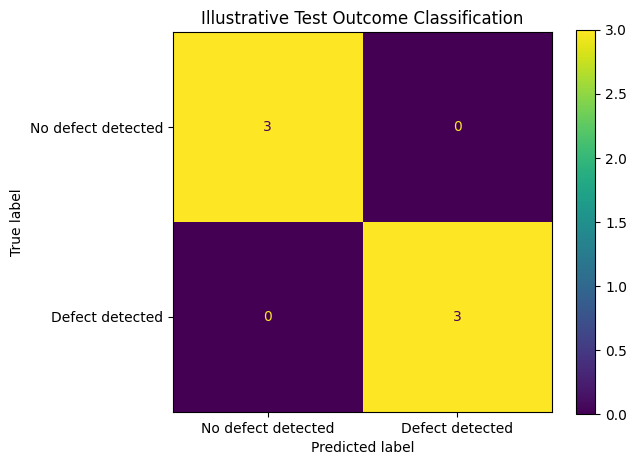

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    predictions,
    target_names=["No defect detected", "Defect detected"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["No defect detected", "Defect detected"]
)
plt.title("Illustrative Test Outcome Classification")
plt.tight_layout()
plt.show()

## Cell 7 — Rank a set of test cases

After training, the model estimates a defect-detection probability for each candidate test case. Sorting by this probability creates a suggested priority order. The probability is an estimate based on the illustrative data; it is not a guarantee that a test will find a defect.

In [7]:
# For demonstration, rank the candidate cases in the example table.
ranked_tests = df.copy()
ranked_tests["predicted_probability"] = model.predict_proba(
    ranked_tests[features]
)[:, 1]

ranked_tests = ranked_tests.sort_values(
    "predicted_probability",
    ascending=False
).reset_index(drop=True)

ranked_tests["priority_rank"] = np.arange(1, len(ranked_tests) + 1)

display(ranked_tests[
    [
        "priority_rank",
        "test_case",
        "predicted_probability",
        "previous_failures",
        "code_changed",
        "execution_time",
        "detected_defect"
    ]
].round(3))

,priority_rank,test_case,predicted_probability,previous_failures,code_changed,execution_time,detected_defect
0,1,Payment,1.00,5,1,8,1
1,2,Checkout,1.00,4,1,7,1
2,3,Order,1.00,4,1,7,1
3,4,Refund,1.00,3,1,6,1
4,5,Coupon,1.00,3,1,5,1
5,6,Inventory,1.00,5,1,8,1
6,7,Discount,1.00,3,1,5,1
7,8,Invoice,1.00,4,1,6,1
8,9,Review,0.93,2,1,4,1
9,10,Registration,0.93,2,1,4,1


## Cell 8 — Visualize the suggested priority order

The chart displays estimated probabilities for the highest-ranked test cases. It is a visualization of the model's suggested order, not proof that the first test will actually find a defect.

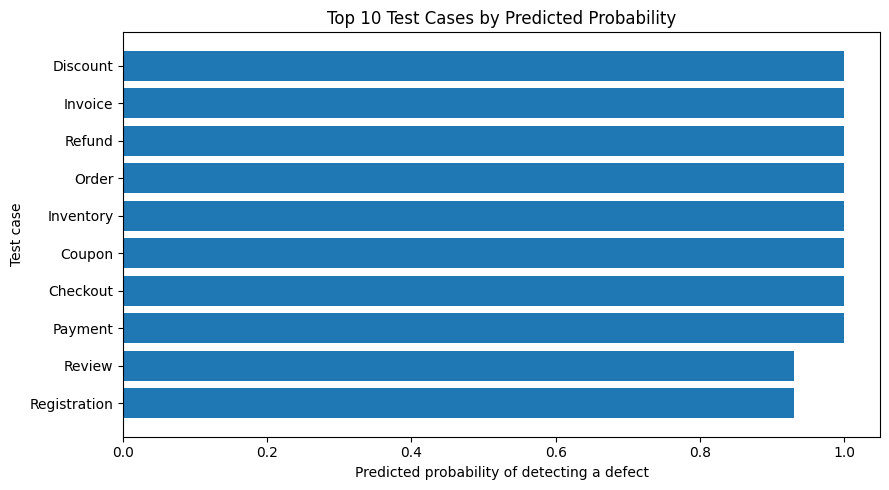

In [8]:
top_n = 10
plot_df = ranked_tests.head(top_n).sort_values(
    "predicted_probability",
    ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(plot_df["test_case"], plot_df["predicted_probability"])
plt.xlabel("Predicted probability of detecting a defect")
plt.ylabel("Test case")
plt.title(f"Top {top_n} Test Cases by Predicted Probability")
plt.tight_layout()
plt.show()

## Cell 9 — Compare with a simple baseline order

A basic baseline may sort test cases by previous failures. This is not necessarily the best prioritization strategy, but it gives students a comparison against the ML-based ranking.

In [9]:
baseline = df.sort_values(
    "previous_failures",
    ascending=False
)[["test_case", "previous_failures"]].reset_index(drop=True)

baseline["baseline_rank"] = np.arange(1, len(baseline) + 1)

comparison = ranked_tests[
    ["test_case", "priority_rank", "predicted_probability"]
].merge(
    baseline[["test_case", "baseline_rank", "previous_failures"]],
    on="test_case"
).sort_values("priority_rank")

display(comparison.round(3))

,test_case,priority_rank,predicted_probability,baseline_rank,previous_failures
0,Payment,1,1.00,1,5
1,Checkout,2,1.00,4,4
2,Order,3,1.00,3,4
3,Refund,4,1.00,8,3
4,Coupon,5,1.00,6,3
5,Inventory,6,1.00,2,5
6,Discount,7,1.00,7,3
7,Invoice,8,1.00,5,4
8,Review,9,0.93,9,2
9,Registration,10,0.93,10,2


## Interpretation and limitations

- Test case prioritization changes execution order; it does not mean lower-ranked tests should be skipped permanently.
- The target here is whether a defect was detected in a historical execution. That label is not the same as proving a test case is intrinsically better.
- Real projects need larger, representative execution histories and leakage-safe splits by time/build.
- Practical prioritization may also consider defect severity, test cost, code coverage, and time constraints.
- This notebook is a classroom baseline, not the official AutoTCP implementation or a reproduction of the paper's results.

### Research reference
For the research implementation and its experimental setup, consult the official AutoTCP repository:
https://github.com/humains-lab/2026-AutoTCP